# 淘宝用户行为分析

使用 Pandas 清洗淘宝行为日志，使用 Matplotlib 绘制行为分布、小时活跃、回访、活跃度分层和加购用户的购买行为。可以另外将清洗后的数据写入 MySQL，或导出 CSV 到 Power BI。

In [1]:
# 导入主要包
import pandas as pd
import matplotlib.pyplot as plt

# 修改：字体统一设置一次，不必每张图重复设置。
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

**连接 MySQL（可选）**

若未设置 `TAOBAO_MYSQL_USER` 和 `TAOBAO_MYSQL_PASSWORD`，数据库步骤会自动跳过。配置方法见 [README](README.md#可选的-mysql-入库)。

In [ ]:
import os

mysql_user = os.environ.get("TAOBAO_MYSQL_USER")
mysql_password = os.environ.get("TAOBAO_MYSQL_PASSWORD")
engine = None

if mysql_user and mysql_password:
    from sqlalchemy import URL, create_engine, text

    mysql_host = os.environ.get("TAOBAO_MYSQL_HOST", "localhost")
    server_url = URL.create(
        "mysql+pymysql",
        username=mysql_user,
        password=mysql_password,
        host=mysql_host,
        query={"charset": "utf8mb4"},
    )

    with create_engine(server_url).begin() as conn:
        conn.execute(text("CREATE DATABASE IF NOT EXISTS taobao_db CHARACTER SET utf8mb4"))

    engine = create_engine(server_url.set(database="taobao_db"))
    print("已连接到项目数据库。")
else:
    print("已跳过 MySQL 配置。")

**读取数据与清洗**

清洗步骤保留原版：读取10万行、设置列名、转换北京时间、筛选九天范围。

In [ ]:
# 读取数据 + 数据清洗 + 总览数据
# 修改：使用项目目录中的相对路径；在本文件夹启动 Notebook 即可。
# 1. 读取CSV文件
df = pd.read_csv(
    "UserBehavior.csv",
    header=None,  # 文件没有表头，这参数不写会报错
    nrows=100000  # 导入 10 万条测试（多了有点卡）
)
# 2. 定义列名
df.columns = ["user_id", "item_id", "category_id", "behavior_type", "timestamp"]
# 时间戳 timestamp ：从 1970 年 1 月 1 日 00:00:00 开始，到某个时刻经过了多少秒

# 3. 时间处理与异常值清洗
# Unix 时间戳 → UTC → 北京时间 → 去掉时区信息
df['datetime'] = (
    pd.to_datetime(df['timestamp'], unit='s', utc=True)
      .dt.tz_convert('Asia/Shanghai')
      .dt.tz_localize(None)
)
# unit='s' 中的 s 指 second ，声明时间戳的单位是“秒”
# utc=True 生成带 UTC 时区信息，tz_convert 转换时区，tz_localize 去掉时区信息

# 记录清洗前数据量
before = len(df)    # 返回 df 行数，记录总共多少条数据

# 只保留 2017-11-25 ～ 2017-12-03 内的数据
start_date = pd.Timestamp('2017-11-25')     # 得到 2017-11-25 00:00:00
end_date = pd.Timestamp('2017-12-04')  # 右边界不包含，因此包含12月3日全天。
# .Timestamp 是 Pandas 对单个时间点的表示方式
df = df[(df['datetime'] >= start_date) & (df['datetime'] < end_date)].copy()
# 清洗后数据量
after = len(df)

print(f"清洗前数据量：{before:,}")     # :,表示给数字添加千位分隔符
print(f"清洗后数据量：{after:,}")
print(f"删除异常时间数据：{before - after:,} 条")
print(f"有效时间范围：{df['datetime'].min()} ~ {df['datetime'].max()}")
# 4. 检查字段及类型
df.info()

# 修改：增加两个简单检查，检查失败时会报错提醒。
assert not df.empty, "清洗后没有数据，请检查时间范围"
assert df['behavior_type'].isin(['pv', 'cart', 'fav', 'buy']).all(), "出现未知行为类型"
print("本部分核对：清洗后非空，行为类型均有效。")

In [ ]:
# 准备 Power BI 使用的数据，复制一份，不影响原来的 df。
powerbi_df = df[['user_id', 'datetime', 'behavior_type']].copy()

# 拆出日期和小时，方便在 Power BI 中拖动使用。
powerbi_df['日期'] = powerbi_df['datetime'].dt.date
powerbi_df['小时'] = powerbi_df['datetime'].dt.hour

# 用户ID改成中文列名；行为仍保留 pv、cart、fav、buy。
powerbi_df = powerbi_df.rename(columns={'user_id': '用户ID'})

# 每一行仍然代表一次行为，不提前汇总。
powerbi_df = powerbi_df[['用户ID', '日期', '小时', 'behavior_type']]

# utf-8-sig 可以帮助软件正确识别中文。
powerbi_df.to_csv('powerbi_data.csv', index=False, encoding='utf-8-sig')

print(f'已导出 {len(powerbi_df):,} 条行为')


已导出 99,956 条行为


**写入 MySQL（可选）**

配置数据库连接后，此步骤会替换 `taobao_db` 中现有的 `user_behavior` 表。

In [ ]:
if engine is not None:
    df.to_sql(
        name="user_behavior",
        con=engine,
        if_exists="replace",
        index=False,
    )
    print("样本数据已写入 MySQL。")
else:
    print("已跳过 MySQL 写入。")

**1. 总览数据分析**

修改仅是名称：“转化漏斗”改为“行为次数分布”。这四种行为的次数没有证明用户按固定顺序转化。

In [5]:
# 总览数据分析
# 修改：直接使用清洗后的 df，去掉原版重复的 pd.read_sql。
# 明确顺序，避免 value_counts 的默认排序影响图中的标签对应。
# 统计行为数量
behavior_count = df['behavior_type'].value_counts().reindex(['pv', 'cart', 'fav', 'buy'], fill_value=0)
# value_counts：统计每一种行为出现了多少次
# 改成中文，.map() 按照一个映射关系，把原来的值转换成新的值
behavior_count.index = behavior_count.index.map({
    'pv': '浏览',
    'cart': '加购',       # "加购"是指加购物车
    'fav': '收藏',
    'buy': '购买'
})

# 关键指标
print("=== 关键指标 ===")
print(f"总行为数：{len(df):,}")
print(f"独立用户数：{df['user_id'].nunique():,}")
print(f"独立商品数：{df['item_id'].nunique():,}")
print("\n行为类型分布：")
print(behavior_count)
assert behavior_count.sum() == len(df), "行为次数合计不一致"
print("本部分核对：各类行为次数合计等于总行为数。")

=== 关键指标 ===
总行为数：99,956
独立用户数：983
独立商品数：64,440

行为类型分布：
behavior_type
浏览    89665
加购     5446
收藏     2744
购买     2101
Name: count, dtype: int64
本部分核对：各类行为次数合计等于总行为数。


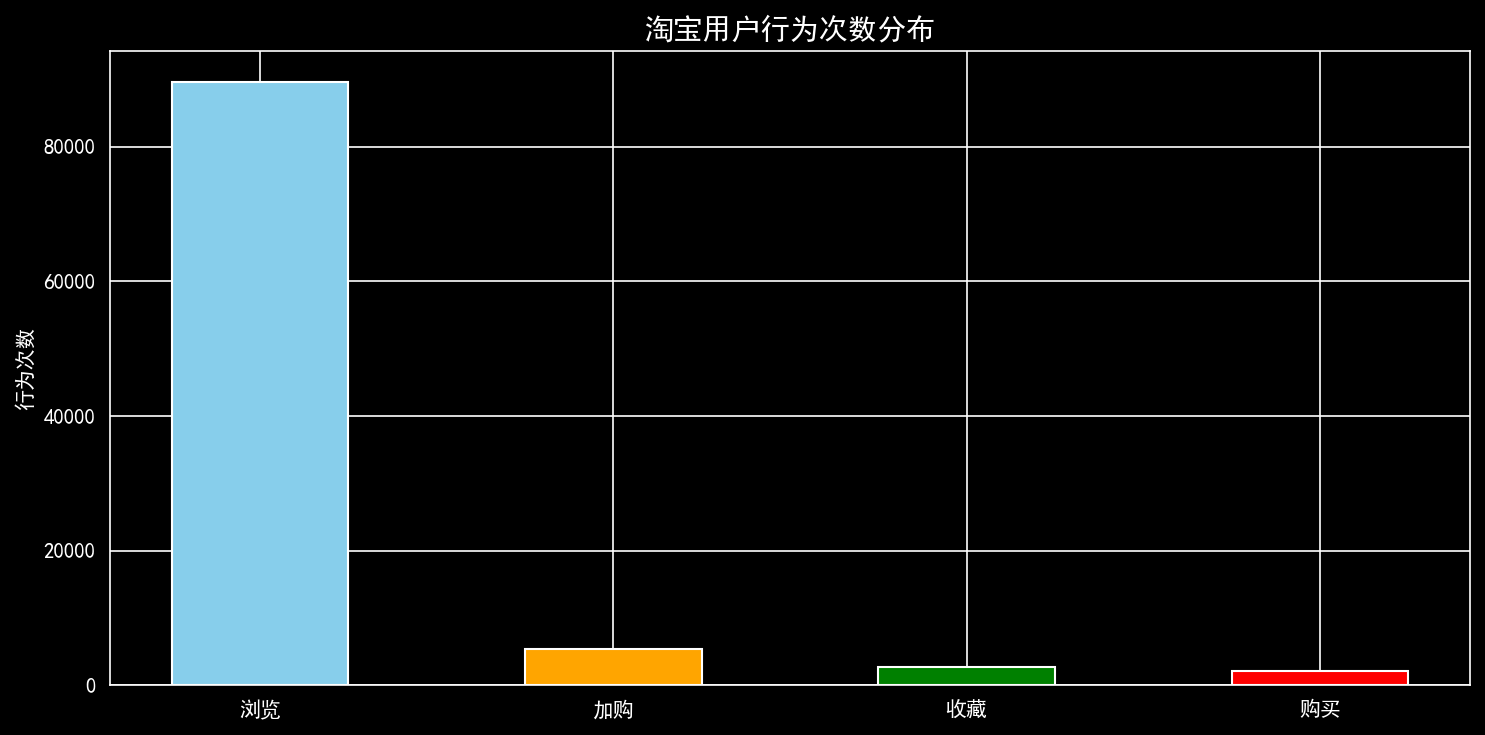

In [6]:
# 画图 - 行为次数分布
# 修改：dpi 从600改成150，减小文件；图题不再称为转化漏斗。
plt.figure(figsize=(10, 5), dpi=150)
plt.bar(behavior_count.index, behavior_count.values, width=0.5,
        color=['skyblue', 'orange', 'green', 'red'])
plt.title("淘宝用户行为次数分布", fontsize=14)
plt.ylabel("行为次数")
plt.tight_layout()
plt.show()

**2. 用户活跃时段分析**

计算保留原版。这是整个九天中在该小时段出现过的去重用户数，不是每天该小时的平均人数。
同一人可能在多个小时出现，因此不能将24个小时的用户数相加当作总用户数。

In [7]:
# 用户活跃时段分析（计算逻辑与原版相同）
# 从 datetime 这一列中，把“小时”提取出来 | .dt.hour/day/...
df['hour'] = df['datetime'].dt.hour

# 统计各小时活跃人数
hour_count = df.groupby('hour')['user_id'].nunique()    # 这里 hour_count 实际上是一个Series(见笔记)
print(hour_count)
# 关键指标
print("=== 用户活跃时段关键指标 ===")
print(f"活跃高峰时段：{hour_count.idxmax()} 点，活跃用户数：{hour_count.max():,}")
# idxmax = index... , 表示找到最大值所对应的 index
print(f"活跃低谷时段：{hour_count.idxmin()} 点，活跃用户数：{hour_count.min():,}")
assert hour_count.max() <= df['user_id'].nunique(), "小时用户数超过总用户数"
print("本部分核对：最高时段人数没有超过全期独立用户数。")

hour
0     300
1     169
2      95
3      68
4      62
5      94
6     183
7     330
8     441
9     522
10    575
11    577
12    571
13    614
14    568
15    594
16    615
17    590
18    566
19    638
20    676
21    708
22    633
23    505
Name: user_id, dtype: int64
=== 用户活跃时段关键指标 ===
活跃高峰时段：21 点，活跃用户数：708
活跃低谷时段：4 点，活跃用户数：62
本部分核对：最高时段人数没有超过全期独立用户数。


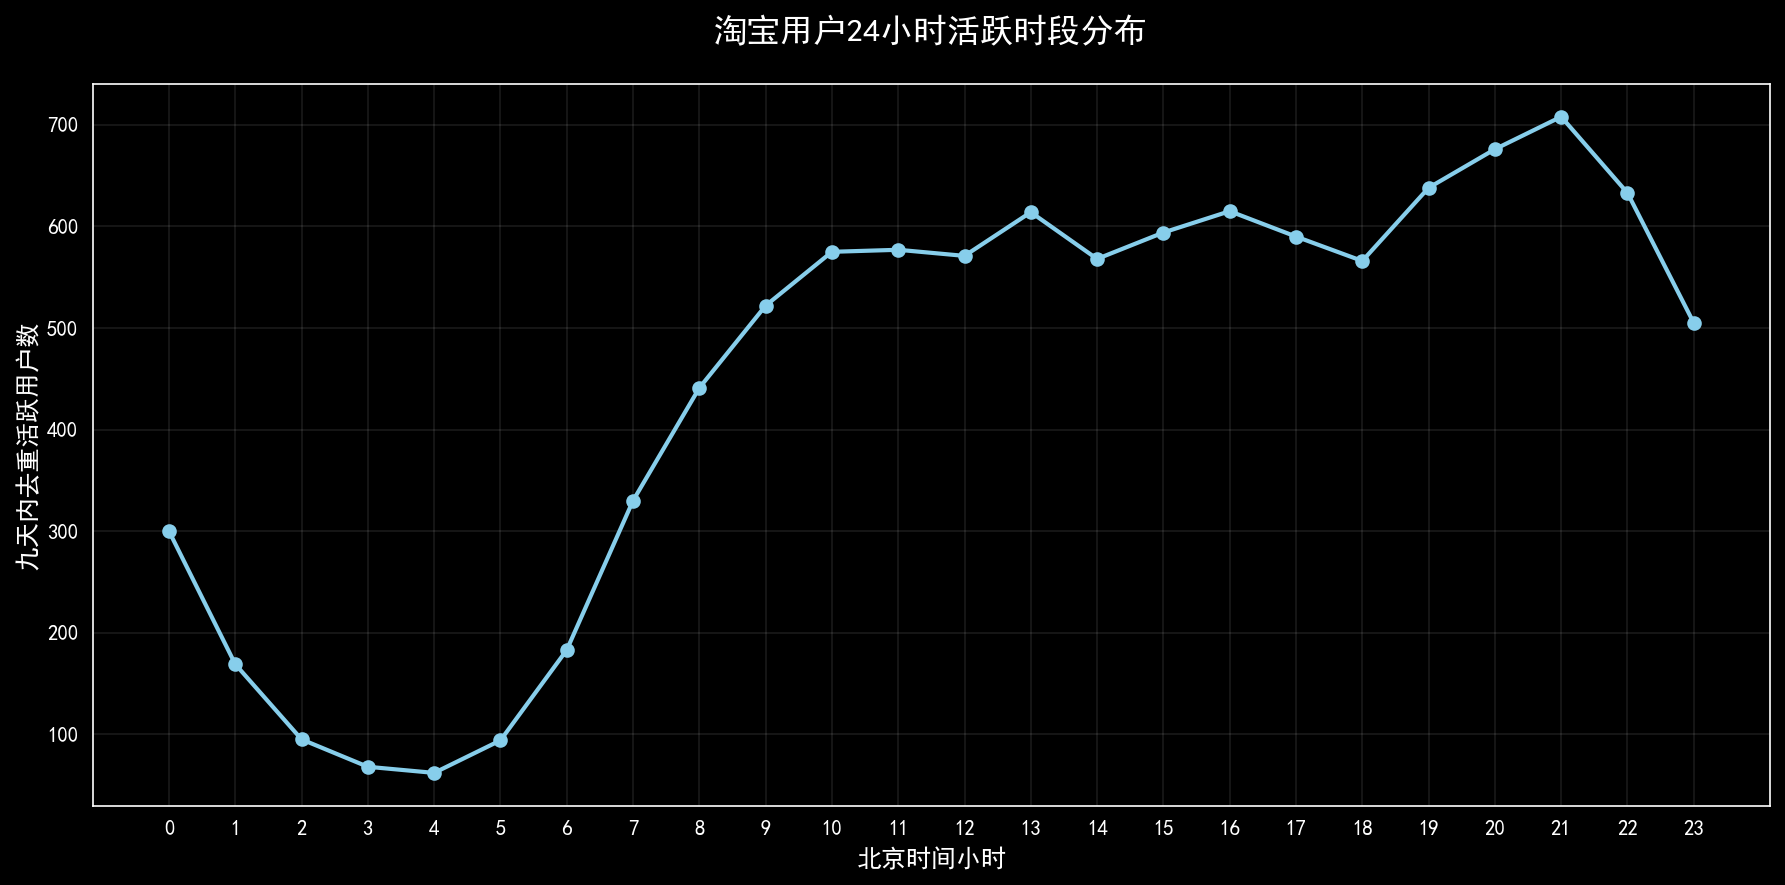

In [8]:
# 画图 - 用户活跃时段分析（保留原版折线图）
plt.figure(figsize=(12, 6), dpi=150)
plt.plot(hour_count.index, hour_count.values, marker='o', color='skyblue', linewidth=2)
# 这里如果 hour_count 是 DataFrame ，参数就得写具体列名了
plt.title('淘宝用户24小时活跃时段分布', fontsize=16, pad=20)
plt.xlabel('北京时间小时', fontsize=12)
plt.ylabel('九天内去重活跃用户数', fontsize=12)
plt.xticks(range(24))
plt.grid(alpha=0.1)
plt.tight_layout()
plt.show()

**3. 用户回访：只看11月25日活跃的固定一批人**

这是本版唯一对计算口径做实质调整的部分。为了容易理解，不再做多组矩阵和加权汇总。

**问题：11月25日活跃的695个人，后面每天还有多少人活跃？**
分母每天都是这695人；分子是这批人当天出现过至少一次行为的人数。
浏览、收藏、加购、购买都算活跃；不要求连续每天回来，也不要求购买。
这些人不是已知的新注册用户，所以图题叫“回访率”，不叫“新用户留存率”。

原版从每人的首次出现日期起算，但后期也用全部983人作分母，其中一些人根本没有足够观察天数。
本版固定第一天这批人，他们都具有完整的Day0～Day8观察机会，避免这个问题。

In [9]:
# 用户回访分析：尽量沿用原版的 normalize、groupby、nunique 写法。
# 修改1：另建 retention_df，不覆盖其他部分仍需要的原始清洗数据 df。
retention_df = df[['user_id', 'datetime']].copy()
# 只保留日期
retention_df['date'] = retention_df['datetime'].dt.normalize()
# .dt.date 通常得到的是 Python 的 date 对象,这里得到的是仍然保持 Pandas 的 datetime 类型，如 2017-11-25 00:00:00

# 修改2：固定11月25日活跃用户这批人，不混合不同首次出现日期的用户。
first_day_users = retention_df.loc[
    retention_df['date'] == start_date, 'user_id'
].unique()
retention_df = retention_df[retention_df['user_id'].isin(first_day_users)].copy()

# 修改3：从统一的11月25日起算天数；固定分母为第一天活跃用户数。
retention_df['days'] = (retention_df['date'] - start_date).dt.days
# 两个 datetime 相减，得到的是 Timedelta，如 3 days
# .dt.days 从 Timedelta 中提取“相差了多少天”，如 3 days 提取出 3
daily_retention = retention_df.groupby('days')['user_id'].nunique()
daily_retention = daily_retention.reindex(range(9), fill_value=0)
daily_retention_pct = (daily_retention / len(first_day_users) * 100).round(2)

print("=== 11月25日活跃用户：每天回访人数 ===")
print(daily_retention)
print("\n=== 每天回访率（%），分母固定 ===")
print(daily_retention_pct)
print(f"固定分母：{len(first_day_users)} 人")

# 修改4：用日期交集再核对Day8，防止只看百分比就认定正确。
last_day_users = df.loc[
    df['datetime'].dt.normalize() == pd.Timestamp('2017-12-03'), 'user_id'
].unique()
day8_check = len(set(first_day_users) & set(last_day_users))
assert daily_retention.loc[0] == len(first_day_users)
assert daily_retention.loc[8] == day8_check
assert daily_retention_pct.between(0, 100).all()
print(f"Day8交集核对：{day8_check}/{len(first_day_users)} = {daily_retention_pct.loc[8]:.2f}%")

# 顺便看整个样本每日活跃人数，帮助判断高值是否只出现在这一个分组。
all_daily_users = df.groupby(df['datetime'].dt.normalize())['user_id'].nunique()
print("\n=== 整个样本的每日活跃人数（解释高回访率用） ===")
print(all_daily_users)
print("本部分核对：计算一致；末两天几乎全样本活跃，回访高值的业务原因尚未确定。")

=== 11月25日活跃用户：每天回访人数 ===
days
0    695
1    553
2    546
3    544
4    543
5    525
6    528
7    682
8    685
Name: user_id, dtype: int64

=== 每天回访率（%），分母固定 ===
days
0    100.00
1     79.57
2     78.56
3     78.27
4     78.13
5     75.54
6     75.97
7     98.13
8     98.56
Name: user_id, dtype: float64
固定分母：695 人
Day8交集核对：685/695 = 98.56%

=== 整个样本的每日活跃人数（解释高回访率用） ===
datetime
2017-11-25    695
2017-11-26    723
2017-11-27    708
2017-11-28    720
2017-11-29    724
2017-11-30    712
2017-12-01    718
2017-12-02    962
2017-12-03    965
Name: user_id, dtype: int64
本部分核对：计算一致；末两天几乎全样本活跃，回访高值的业务原因尚未确定。


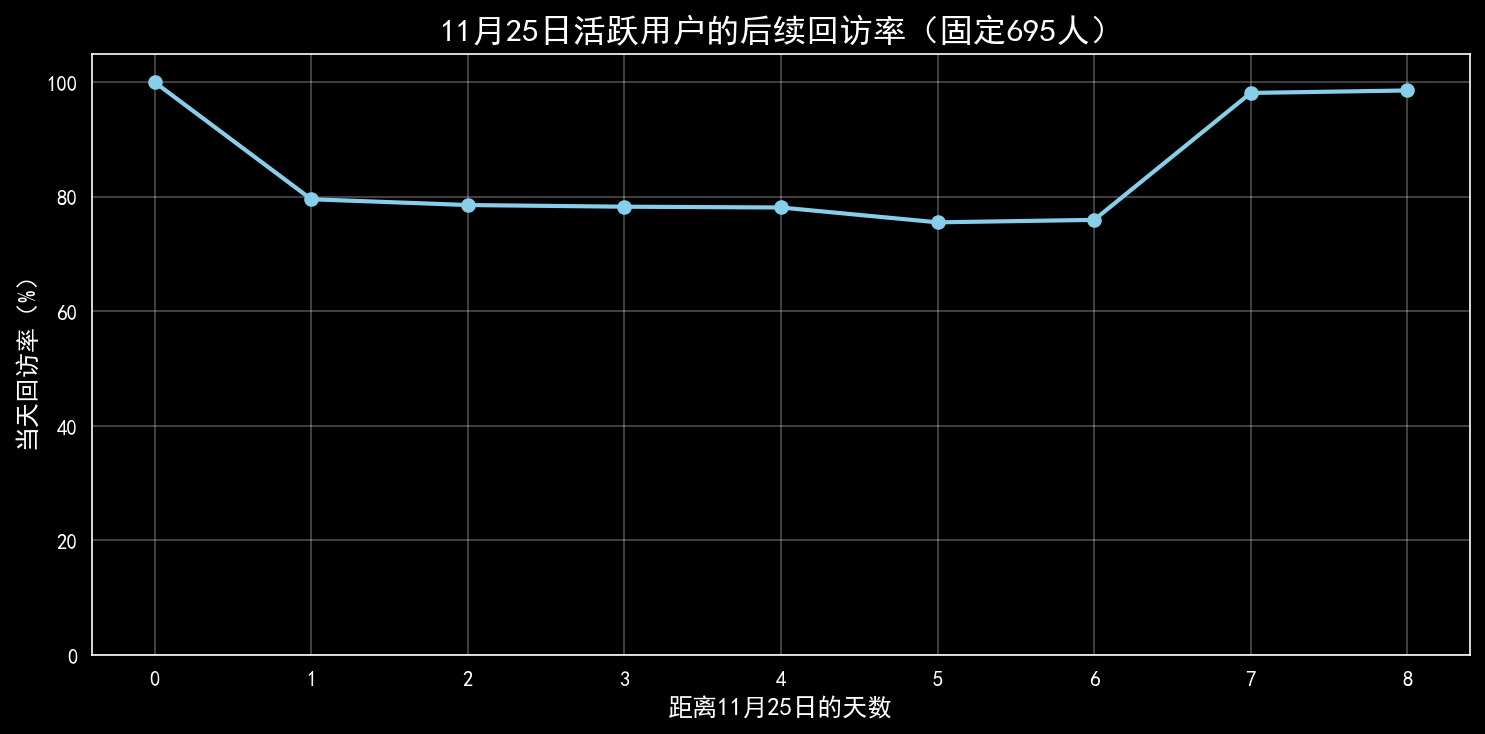

In [10]:
# 画图 - 固定用户组每天回访率（仍是原版风格的单条折线）
plt.figure(figsize=(10, 5), dpi=150)
plt.plot(daily_retention_pct.index, daily_retention_pct.values,
         marker='o', color='skyblue', linewidth=2)
plt.title('11月25日活跃用户的后续回访率（固定695人）', fontsize=16)
plt.xlabel('距离11月25日的天数', fontsize=12)
plt.ylabel('当天回访率（%）', fontsize=12)
plt.xticks(daily_retention_pct.index)
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**回访结果应该如何解释**

Day8 = 685/695 = 98.56%。意思是：第一天的695人中，685人在12月3日出现过行为。
核对数字一致，**不等于证明淘宝新用户留存良好**。
全样本983人中，12月2日有962人活跃，12月3日有965人活跃；最后两天普遍活跃，
这解释了为何计算出的回访比例很高，但数据没有提供导致这一现象的原因。
本样本按用户集中排列，前10万行不是随机样本，且可能截断末尾用户。
因此保留统计事实，不据此写运营效果结论，也不为了降低数值修改数据。

**4. 用户活跃度分层**

一天可能浏览多次，活跃一天并不等于只发生一次行为。

In [11]:
# 用户活跃度分层
user_day_df = df[['user_id', 'datetime']].copy()
# 提取日期
user_day_df['date'] = user_day_df['datetime'].dt.normalize()
# 统计每个用户实际活跃了多少天
user_days = (
    user_day_df.groupby('user_id', as_index=False)['date'].nunique()
    .rename(columns={'date': 'active_days'})
)       # 这里 user_days 是一个 DataFrame

# 定义活跃度分层规则
def get_active_level(day_count):
    if day_count >= 7:
        return '高频活跃'
    elif day_count >= 5:
        return '较高活跃'
    elif day_count >= 3:
        return '中频活跃'
    elif day_count >= 2:
        return '低频活跃'
    else:
        return '单日活跃'

# 给每个用户打标签
user_days['level'] = user_days['active_days'].apply(get_active_level)
# .apply() 函数逐个应用到 active_days 的每一个值上
# Series.apply(函数)
# 统计各活跃度用户数量
level_count = user_days['level'].value_counts()
# 这是一个 Series ，‘level’是索引
# 输出占比结果
level_pct = (
    user_days['level']
    .value_counts(normalize=True)       # 前面 level_count 的升级版，人数数量换成占比
    .mul(100)       # multiply，乘法
    .round(2)
)
print("=== 用户活跃度分层 ===")
print(level_count)
print("\n=== 用户活跃度占比（%） ===")
print(level_pct)
assert level_count.sum() == df['user_id'].nunique()
print("本部分核对：各层人数合计等于全期独立用户数。")

=== 用户活跃度分层 ===
level
高频活跃    631
较高活跃    250
中频活跃    102
Name: count, dtype: int64

=== 用户活跃度占比（%） ===
level
高频活跃    64.19
较高活跃    25.43
中频活跃    10.38
Name: proportion, dtype: float64
本部分核对：各层人数合计等于全期独立用户数。


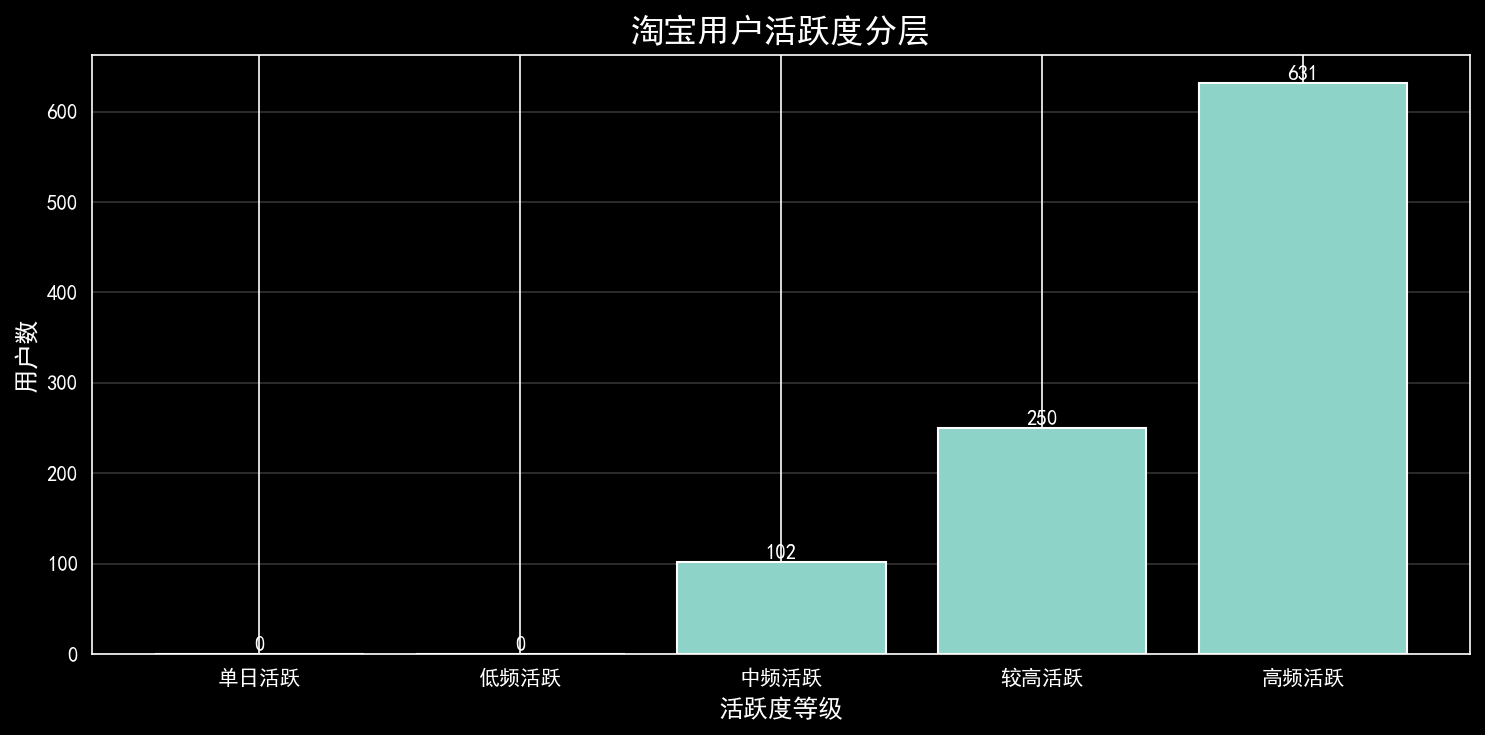

In [12]:
# 画图 - 活跃度分层柱状图（保留原版）
# 按照活跃度从低到高排列
order = ['单日活跃', '低频活跃', '中频活跃', '较高活跃', '高频活跃']
level_count_plot = level_count.reindex(order, fill_value=0)
plt.figure(figsize=(10, 5), dpi=150)
plt.bar(level_count_plot.index, level_count_plot.values)
plt.title('淘宝用户活跃度分层', fontsize=16)
plt.xlabel('活跃度等级', fontsize=12)
plt.ylabel('用户数', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.2)
# 在柱子上显示具体人数
for i, value in enumerate(level_count_plot.values):
    plt.text(i, value, str(value), ha='center', va='bottom')
plt.tight_layout()
plt.show()

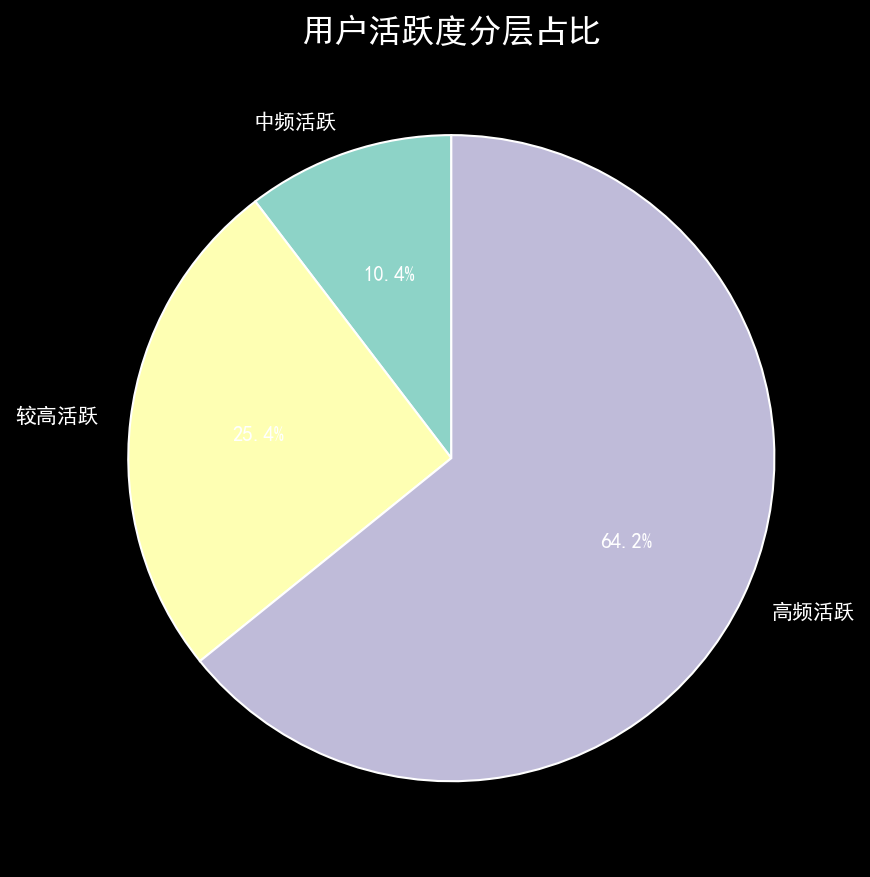

In [13]:
# 画图 - 活跃度分层饼图（保留原版）
level_pct_plot = level_pct.reindex(order, fill_value=0)
# 去掉占比为0的类别
level_pct_plot = level_pct_plot[level_pct_plot > 0]
plt.figure(figsize=(6, 6), dpi=150)
plt.pie(level_pct_plot.values, labels=level_pct_plot.index,
        autopct='%1.1f%%', startangle=90)
plt.title('用户活跃度分层占比', fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
# 补充：各活跃层级的购买行为贡献，保留原有分层规则和人数占比。
# 数据没有订单编号，这里统计 buy 记录条数，称为“购买行为次数”。
# 1. 统计每个用户的购买行为次数
user_buy_count = (
    df.loc[df['behavior_type'] == 'buy']
    .groupby('user_id').size()
    .reset_index(name='buy_count')
)
# .size() 统计每个用户有多少条购买记录，不是对商品去重。

# 2. 将购买次数补到全体分层用户中
user_purchase_df = user_days.merge(user_buy_count, on='user_id', how='left')
# how='left' 保留 user_days 中的所有用户，未购买用户不能被删掉。
user_purchase_df['buy_count'] = user_purchase_df['buy_count'].fillna(0).astype(int)
# .fillna(0) 将没有购买记录的用户补为0；.astype(int) 将次数转成整数。
user_purchase_df['is_buyer'] = user_purchase_df['buy_count'] > 0

# 3. 按活跃度汇总人数、购买行为次数和购买用户数
level_purchase_summary = (
    user_purchase_df.groupby('level')
    .agg(
        用户数=('user_id', 'size'),
        购买行为次数=('buy_count', 'sum'),
        购买用户数=('is_buyer', 'sum')
    )
    .reindex(order, fill_value=0)
)
# .agg() 同时计算多个指标；布尔值求和就是购买用户数。
# .reindex() 沿用前面的五层顺序，没有用户的层级保留为0。

# 4. 计算人数占比、购买贡献及层内购买表现
level_purchase_summary['用户占比（%）'] = (
    level_purchase_summary['用户数'] / len(user_days) * 100
)
total_buy_count = level_purchase_summary['购买行为次数'].sum()
level_purchase_summary['购买贡献占比（%）'] = (
    level_purchase_summary['购买行为次数'] / total_buy_count * 100
    if total_buy_count > 0 else float('nan')
)
# 购买贡献占比 = 该层购买行为次数 / 全部用户购买行为次数。
level_user_count = level_purchase_summary['用户数'].replace(0, float('nan'))
# 空层级没有可计算的人均表现，用空值避免除以0。
level_purchase_summary['层内购买用户占比（%）'] = (
    level_purchase_summary['购买用户数'] / level_user_count * 100
)
level_purchase_summary['人均购买次数'] = (
    level_purchase_summary['购买行为次数'] / level_user_count
)
# 人均购买次数的分母是该层全部用户，包含未购买用户。
level_purchase_summary = level_purchase_summary[[
    '用户数', '用户占比（%）', '购买行为次数', '购买贡献占比（%）',
    '购买用户数', '层内购买用户占比（%）', '人均购买次数'
]]
level_purchase_summary.index.name = '活跃度等级'

print("=== 各活跃层级的购买行为贡献 ===")
print(level_purchase_summary.to_string(float_format=lambda value: f'{value:.2f}', na_rep='—'))
print("注：占比单位为%；— 表示该层没有用户，无法计算层内比例或人均值。")
assert level_purchase_summary['用户数'].sum() == df['user_id'].nunique()
assert level_purchase_summary['购买行为次数'].sum() == (df['behavior_type'] == 'buy').sum()
print("本部分核对：各层人数、购买行为次数分别与全期总量一致。")


=== 各活跃层级的购买行为贡献 ===
       用户数  用户占比（%）  购买行为次数  购买贡献占比（%）  购买用户数  层内购买用户占比（%）  人均购买次数
活跃度等级                                                             
单日活跃     0     0.00       0       0.00      0            —       —
低频活跃     0     0.00       0       0.00      0            —       —
中频活跃   102    10.38      88       4.19     49        48.04    0.86
较高活跃   250    25.43     341      16.23    145        58.00    1.36
高频活跃   631    64.19    1672      79.58    477        75.59    2.65
注：占比单位为%；— 表示该层没有用户，无法计算层内比例或人均值。
本部分核对：各层人数、购买行为次数分别与全期总量一致。


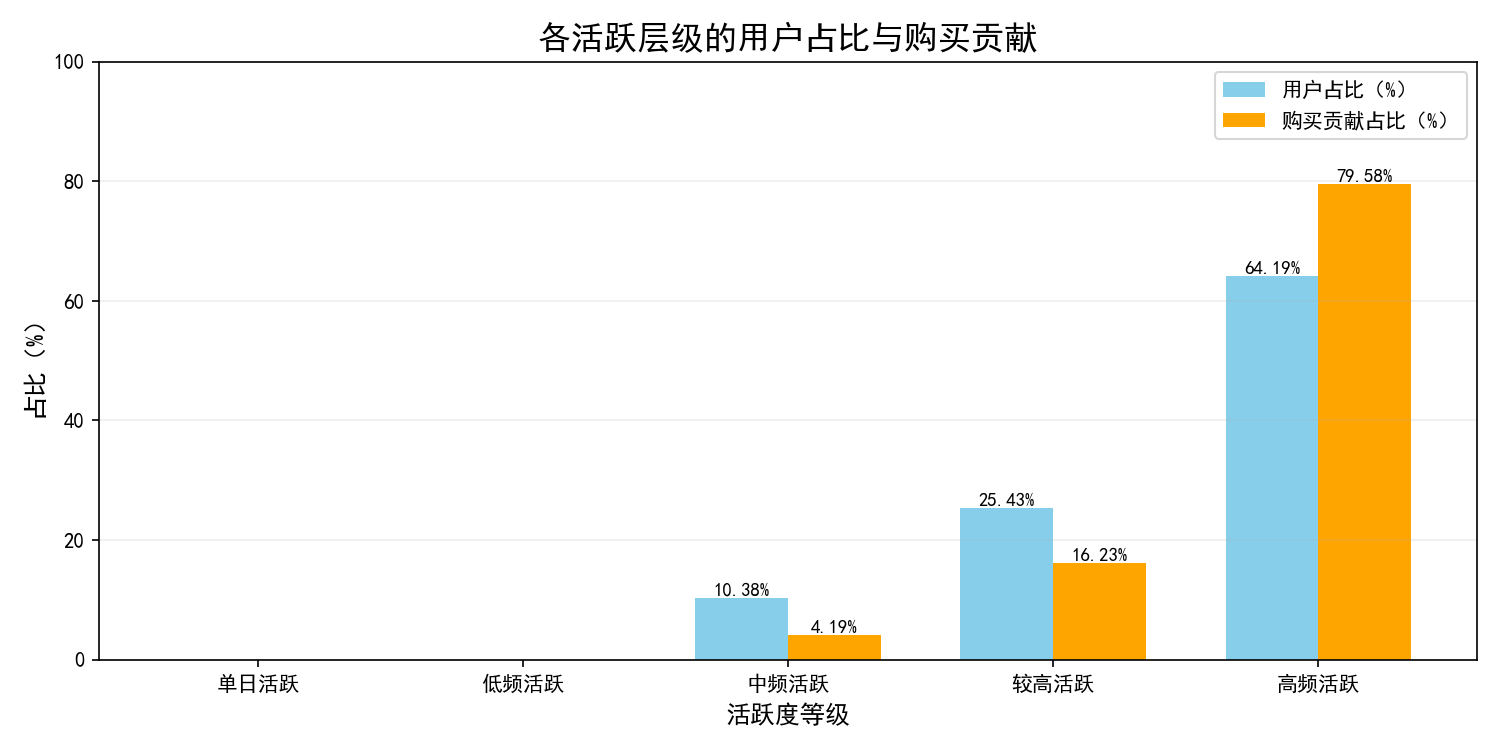

In [ ]:
# 补充：画图 - 各层用户占比与购买贡献对比
# 两组柱子分别表示用户规模和购买贡献，便于比较购买贡献是否高于人数占比。
level_purchase_ax = level_purchase_summary[[
    '用户占比（%）', '购买贡献占比（%）'
]].plot(kind='bar', figsize=(10, 5), width=0.7,
        color=['skyblue', 'orange'], rot=0)
level_purchase_ax.set_title('各活跃层级的用户占比与购买贡献', fontsize=16)
level_purchase_ax.set_xlabel('活跃度等级', fontsize=12)
level_purchase_ax.set_ylabel('占比（%）', fontsize=12)
level_purchase_ax.set_ylim(0, 100)
level_purchase_ax.grid(axis='y', alpha=0.2)
# 在有贡献的柱子上显示占比；空层级仍保留在横轴上。
for bar in level_purchase_ax.patches:
    if bar.get_height() > 0:
        level_purchase_ax.text(
            bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f'{bar.get_height():.2f}%', ha='center', va='bottom', fontsize=9
        )
plt.tight_layout()
plt.show()


**5. 加购用户的购买行为**

计算完全保留原版，不引入商品匹配、时间窗口或新的表。
仅修正名称：这是“有加购、但九天里没有任何购买行为的用户”，不是“未付款”。
用户加购A、购买B，也会被归入“有购买行为”；这里没有证明加购商品购买成功。

In [14]:
# 加购用户购买行为分析（保留原版集合逻辑）
# 每个用户的行为集合，这里 set 的作用是汇总成集合（自动去重）
user_actions = df.groupby('user_id')['behavior_type'].apply(set).reset_index()
# 统计有多少人加购但没买，这里 set 的作用是把括号里面的东西转换成 Python 集合
cart_users = set(user_actions[
    user_actions['behavior_type'].apply(lambda x: 'cart' in x)
]['user_id'])
buy_users = set(user_actions[
    user_actions['behavior_type'].apply(lambda x: 'buy' in x)
]['user_id'])

cart_only = cart_users - buy_users  # 这里是取差集而不是减法
# 原版称“加购未付款的用户”；这里仅表示观察期内无任何购买行为，不能证明未付款。
total_cart = len(cart_users)
cart_no_buy_num = len(cart_only)
cart_no_buy_rate = (cart_no_buy_num / total_cart) * 100 if total_cart > 0 else 0

print("=== 加购用户购买行为分析 ===")
print(f"总加购用户数：{total_cart:,}")
print(f"观察期内没有任何购买行为的加购用户数：{cart_no_buy_num:,}")
print(f"占加购用户比例：{cart_no_buy_rate:.2f}%")
# 修改：直接按行为取用户集合，独立核对原版汇总集合的结果。
direct_cart = set(df.loc[df['behavior_type'] == 'cart', 'user_id'])
direct_buy = set(df.loc[df['behavior_type'] == 'buy', 'user_id'])
assert cart_users == direct_cart
assert cart_only == direct_cart - direct_buy
print("本部分核对：两种集合统计一致；指标不解释为支付状态。")

=== 加购用户购买行为分析 ===
总加购用户数：723
观察期内没有任何购买行为的加购用户数：196
占加购用户比例：27.11%
本部分核对：两种集合统计一致；指标不解释为支付状态。


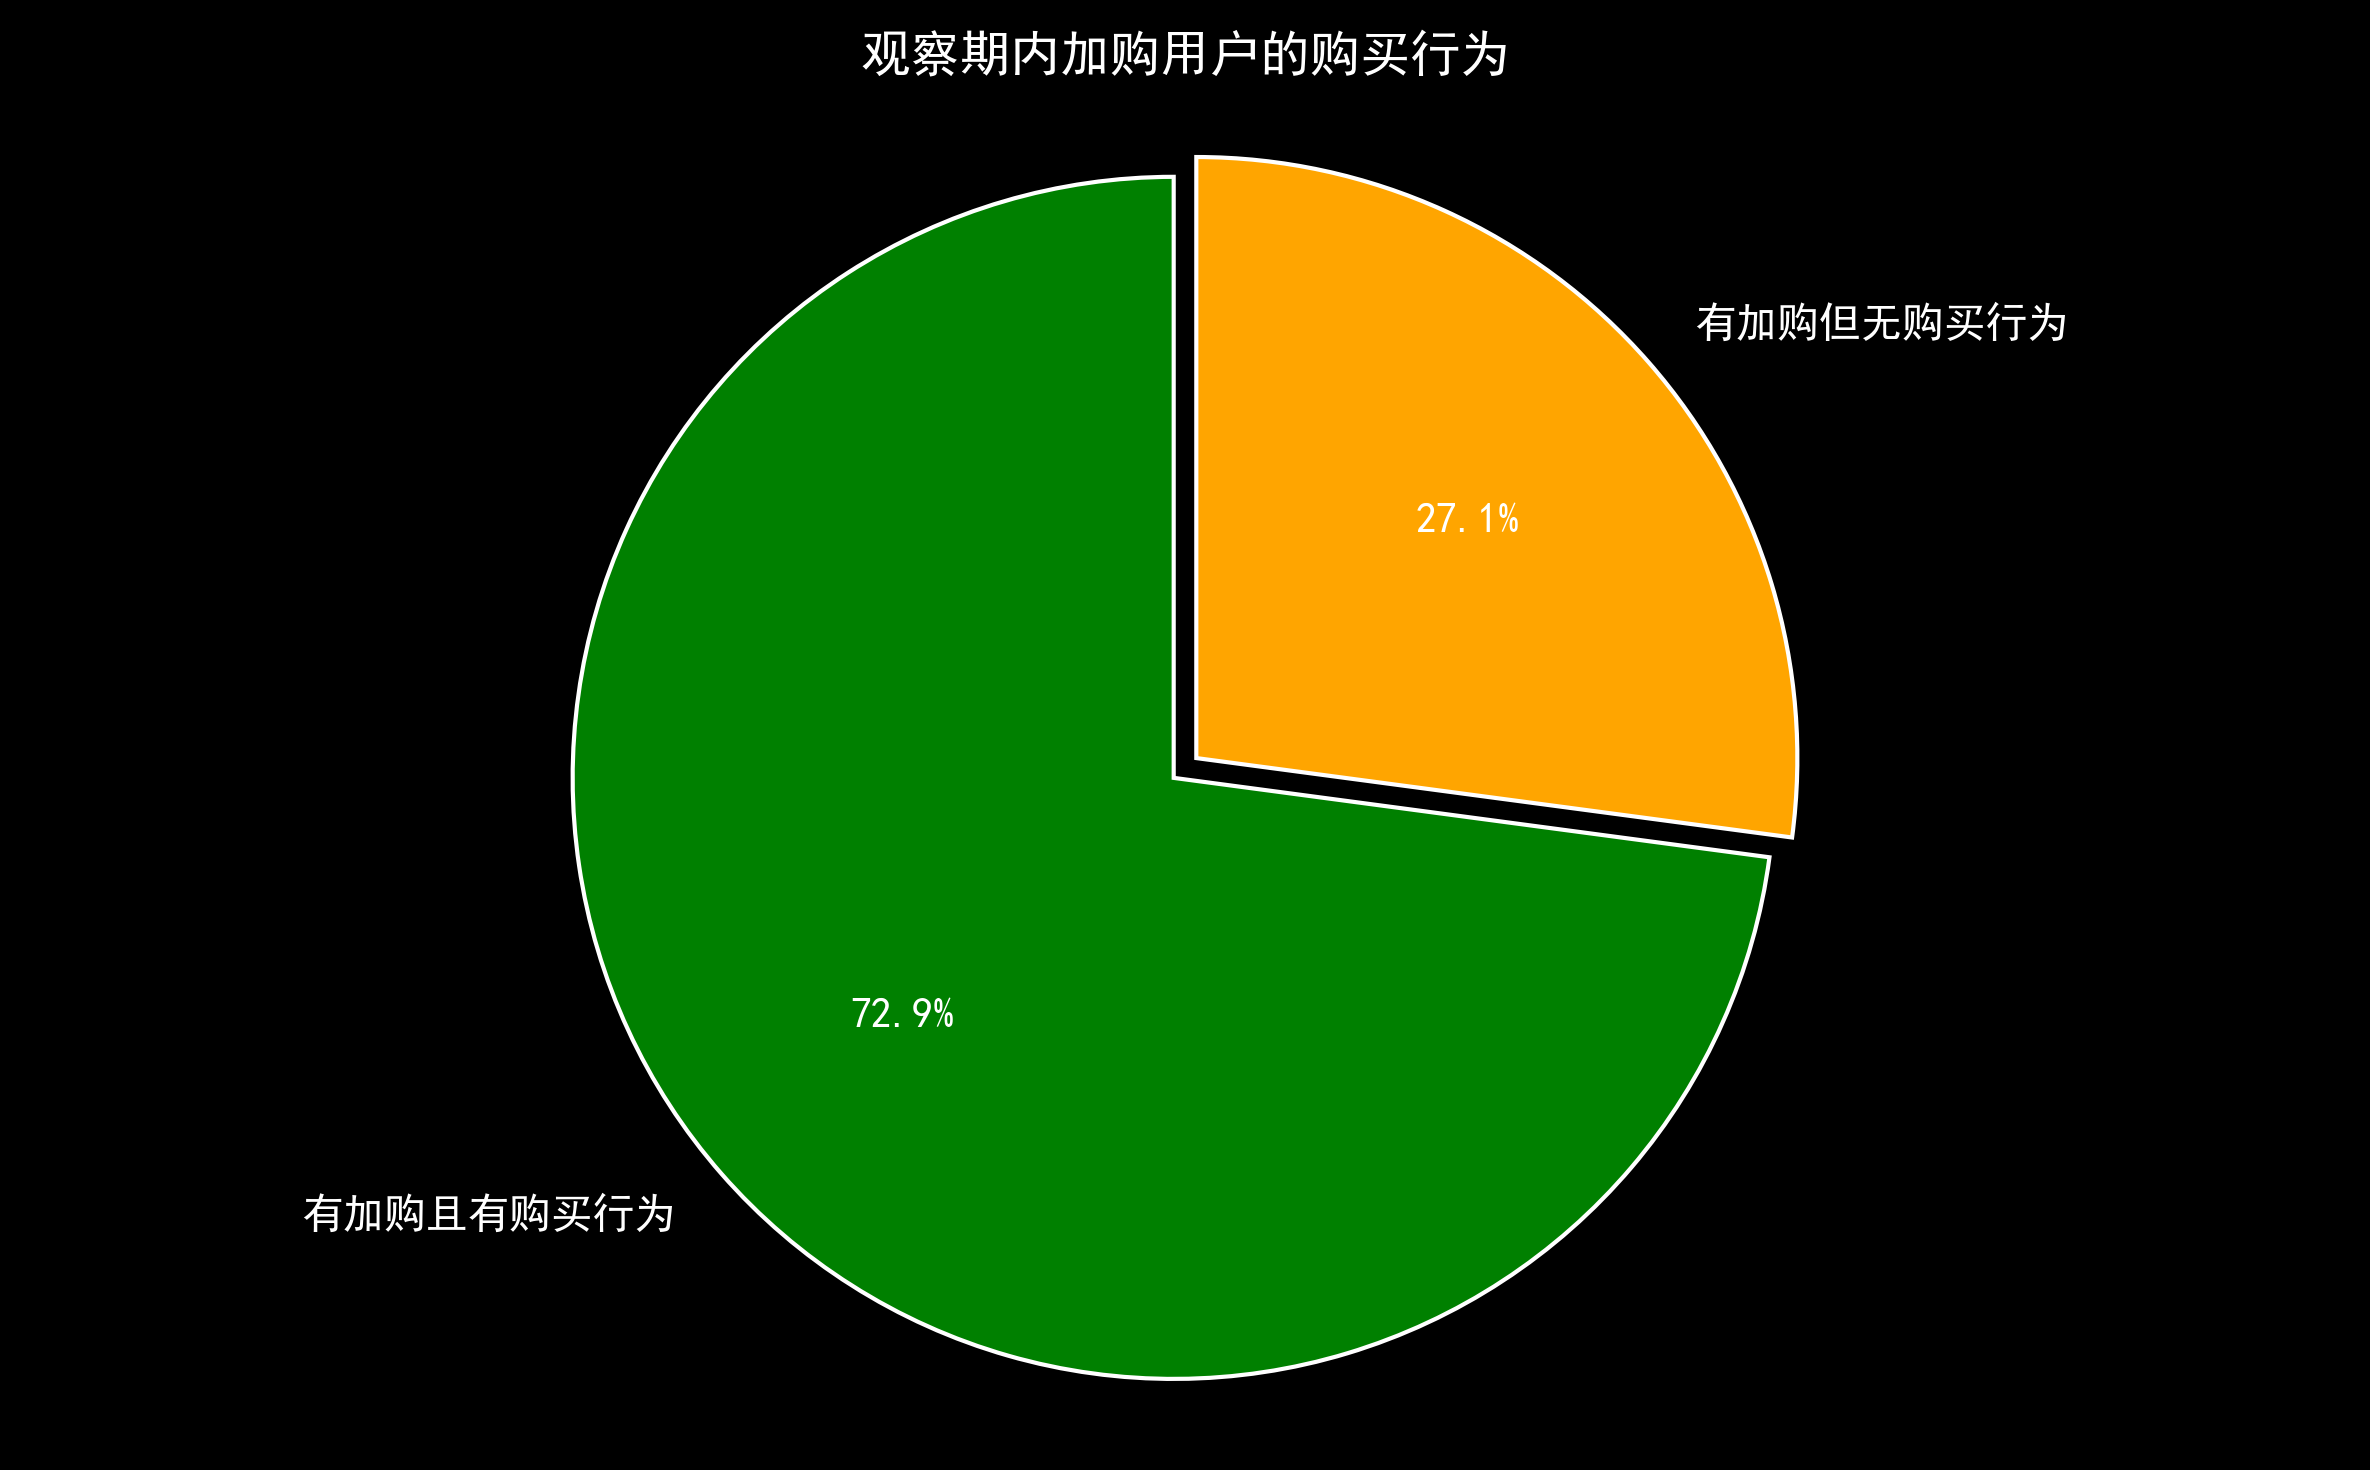

In [16]:
# 画图 - 加购用户的购买行为（保留原版饼图，只改文案）
plt.figure(figsize=(8, 5), dpi=300)
labels = ['有加购且有购买行为', '有加购但无购买行为']
sizes = [total_cart - cart_no_buy_num, cart_no_buy_num]
plt.pie(sizes, explode=(0, 0.05), labels=labels,
        colors=['green', 'orange'], autopct='%1.1f%%', startangle=90)
plt.title('观察期内加购用户的购买行为')
plt.axis('equal')  # 保证饼图是正圆
plt.tight_layout()
plt.show()

**与原版对照及本次审查**

| 部分 | 原版 | 本版 |
|---|---|---|
| 读取清洗 | 前10万行、北京时间、九天范围 | 相同；改用相对路径，加简单检查 |
| 数据来源 | 各部分重复从MySQL读取 | 各部分直接使用清洗后的df，副本不覆盖原数据 |
| 行为总览 | 行为次数，图题叫漏斗 | 数字相同，图题改为行为次数分布 |
| 小时活跃 | 按小时去重用户 | 相同，只补清楚口径 |
| 留存 | 不同首次日期混合，后期分母仍用983人 | 固定11/25这批695人，观察后续回访；单条曲线 |
| 活跃分层 | 按活跃天数分层 | 相同，仅将单次活跃改成单日活跃 |
| 加购 | 加购用户集合减购买用户集合 | 相同，只改为“无购买行为”，不称未付款 |

本次分析代码已运行；基础结果与原版一致：99,956条行为、983个用户、64,440个商品；
小时高峰21点708人，低谷4点62人；加购723人，其中196人没有任何购买行为，占27.11%。
回访Day8的685/695经日期交集核对成立，但高回访的业务原因未确认。
没有用复杂的新指标替换原分析；MySQL两段保留，本次未执行。